# 객체 검출(Object Detection): 공사 현장 개인보호구(PPE) 11클래스 검출

이 노트북은 공사 현장 이미지에서 **사람(Person)**과 **안전모(helmet), 조끼(vest), 장갑(gloves), 안전화(boots)** 등 총 11가지 클래스의 개인보호구(PPE) 착용 여부를 직사각형 바운딩 박스(Bounding Box)로 검출하는 실습 자료입니다. 화면 내 객체의 위치와 종류를 박스로 찾아내면, 현장에 몇 명이 있는지 그리고 안전장비를 제대로 착용했는지를 즉시 파악하고 집계할 수 있습니다.

실습에 사용되는 압축 파일(`zip`)에는 학습·검증·테스트용 이미지 데이터셋과 사전 학습된 YOLO 가중치 파일(`runs/train/weights/best.pt`)이 포함되어 있습니다. 노트북 하단의 **7번(테스트 평가)**과 **8번(추론 및 시연)** 섹션에서는 이 가중치 파일을 불러와 결과를 확인하며, 직접 모델을 학습하거나 추론하는 전체 코드가 각 셀에 단계별로 구현되어 있습니다.

*참고: 코랩의 로컬 공간인 `/content` 디렉터리는 세션이 종료되면 초기화되므로, 원본 `zip` 파일은 본인의 구글 드라이브에 보관해 두는 것이 안전합니다.*


## 1. 데이터 다운로드 경로 및 환경 변수 설정

실습 데이터를 내려받기 위해 구글 드라이브 공유 링크와 저장 경로를 설정합니다. 본인의 드라이브에 있는 데이터셋 `zip` 파일을 우클릭하여 공유 설정을 **'링크가 있는 모든 사용자'**로 변경한 뒤, 복사한 링크를 아래 코드의 `ZIP_URL` 변수에 입력해 주세요.

구글 드라이브에서 100MB 이상의 대용량 파일을 받을 때 일반 `wget` 명령어를 사용하면 바이러스 검사 확인 페이지가 대신 다운로드되는 문제가 발생합니다. 따라서 이후 단계에서는 드라이브 링크일 경우 전용 다운로더인 `gdown`을 사용하고, 일반 웹 URL일 경우에만 `wget`을 사용하도록 처리합니다.


In [1]:
# 데이터셋 압축 파일이 위치한 구글 드라이브 공유 링크
ZIP_URL = "/".join(["https:", "", "drive.google.com", "file", "d", "1rpq909ldsZ9paWCyOdBCXio_nYNFp49O", "view?usp=sharing"])

# 수행할 과제 이름 정의 (폴더명으로 사용됨)
TASK = "object_detection"
# 코랩 환경 내 압축 파일을 저장할 경로
ZIP_PATH = "/content/02_object_detection.zip"
# 압축 해제 후 데이터셋과 가중치가 위치할 최종 디렉터리 경로
DST = f"/content/{TASK}"


## 2. 필수 패키지 및 한글 폰트 설치

구글 드라이브 파일 다운로드를 위한 `gdown`과 YOLO 모델 학습 및 추론을 위한 `ultralytics` 라이브러리를 설치합니다. 또한, 시각화 결과 이미지의 범례와 캡션에 한글 클래스 이름을 깨짐 없이 출력하기 위해 리눅스 시스템용 한글 폰트(`Noto CJK`, `나눔고딕`)를 함께 설치하고 로드 함수를 정의합니다.


In [2]:
# 구글 드라이브 대용량 파일 다운로드를 위한 gdown 패키지 설치 (-q 옵션으로 출력 최소화)
!pip install -q gdown


In [3]:
# YOLO 모델 사용을 위한 ultralytics 패키지 설치 (8.3 이상, 9 미만 버전 지정)
!pip install -q "ultralytics>=8.3,<9"
# 우분투 패키지 목록 업데이트 및 한글 폰트(Noto CJK, 나눔폰트) 설치
!apt-get -qq update
!apt-get -qq install -y fonts-noto-cjk fonts-nanum

from pathlib import Path
from PIL import ImageFont


def hangul_font(size=14):
    """시스템에 설치된 한글 폰트 경로를 순차적으로 탐색하여 PIL ImageFont 객체로 반환하는 함수"""
    # 탐색할 한글 폰트 파일 경로 및 TTC 폰트 인덱스 후보 목록
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
        ("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf", None),
    ):
        # 해당 경로에 폰트 파일이 존재하지 않으면 다음 후보로 이동
        if not Path(path).exists():
            continue
        try:
            # TTC 파일인 경우 index 옵션을 지정하여 폰트 로드
            kw = {"index": index} if index is not None else {}
            font = ImageFont.truetype(path, size, **kw)
            print("hangul_font", path)
            return font
        except OSError:
            # 폰트 파일 로드 중 오류가 발생하면 다음 후보로 이동
            continue
    # 사용 가능한 한글 폰트를 찾지 못한 경우 안내 메시지 출력 후 None 반환
    print("hangul_font missing. 범례는 영문으로 적는다.")
    return None


# 한글 폰트가 정상적으로 로드되는지 테스트 실행
hangul_font()


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 7.9 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Selecting previously unselected package fonts-noto-cjk.
Preparing to unpack .../fonts-noto-cjk_1%3a20230817+repack1-3_all.deb ...
Unpacking fonts-noto-cjk (1:20230817+repack1-3) ...
Setting up fonts-nanum (20200506-1) ...
Setting up fonts-noto-cjk (1:20230817+repack1-3) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
hangul_font /usr/s

## 3. 데이터셋 압축 파일 다운로드 및 압축 해제

앞서 설정한 `ZIP_URL`로부터 데이터셋 압축 파일을 내려받고 `/content` 경로에 압축을 해제합니다. 이미 파일이 정상적으로 다운로드되어 있다면 중복 다운로드를 건너뛰며, 압축 해제 후에는 PyTorch 및 GPU(CUDA) 환경이 제대로 준비되었는지 점검합니다.


In [4]:
from pathlib import Path
import os


def fetch_zip(url, dest):
    """지정된 URL(구글 드라이브 또는 일반 웹 링크)에서 zip 파일을 다운로드하는 함수"""
    url = (url or "").strip()
    # URL이 비어있거나 안내 문구가 그대로 남아있는 경우 실행 중단 및 오류 출력
    if not url or "여기에" in url:
        raise SystemExit(
            "위 셀 ZIP_URL에 구글 드라이브 공유 링크(또는 직접 zip 주소)를 넣는다."
        )

    # URL 문자열을 기반으로 구글 드라이브 링크인지 여부 판별
    is_drive = "drive.google.com" in url or "docs.google.com" in url

    dest = Path(dest)
    # 이미 파일이 존재하고 크기가 10KB 이상이면(정상 파일이면) 재다운로드 생략
    if dest.exists() and dest.stat().st_size > 10_000:
        print("이미 받은 파일이 있다:", dest, dest.stat().st_size, "bytes")
        return

    # 저장할 상위 폴더가 없으면 생성
    dest.parent.mkdir(parents=True, exist_ok=True)

    # 셸 명령어(!gdown, !wget)에서 참조할 수 있도록 환경 변수에 등록
    os.environ["ZIP_URL"] = url
    os.environ["ZIP_PATH"] = str(dest)
    if is_drive:
        # 구글 드라이브 공유 링크인 경우 --fuzzy 옵션으로 파일 ID를 추출해 다운로드
        !gdown --fuzzy "$ZIP_URL" -O "$ZIP_PATH"
    else:
        # 일반 다운로드 링크인 경우 wget으로 이어받기(-c) 수행
        !wget -c -O "$ZIP_PATH" "$ZIP_URL"

    print("받음", dest, dest.stat().st_size, "bytes")


# 설정한 URL에서 압축 파일 다운로드 실행
fetch_zip(ZIP_URL, ZIP_PATH)


Downloading...
From (original): https://drive.google.com/uc?id=1rpq909ldsZ9paWCyOdBCXio_nYNFp49O
From (redirected): https://drive.google.com/uc?id=1rpq909ldsZ9paWCyOdBCXio_nYNFp49O&confirm=t&uuid=6a38769c-ef84-4404-a663-e25b332eb705
To: /content/02_object_detection.zip
100% 190M/190M [00:03<00:00, 48.7MB/s]
받음 /content/02_object_detection.zip 189653119 bytes


In [5]:
# 기존에 압축 해제된 폴더가 있다면 충돌 방지를 위해 삭제
!rm -rf {DST}


In [6]:
# 다운로드한 zip 파일을 /content 디렉터리에 조용히(-q) 덮어쓰기(-o) 모드로 압축 해제
!unzip -q -o {ZIP_PATH} -d /content


In [7]:
from pathlib import Path
import torch
from IPython.display import display
from PIL import Image

# 압축 해제된 프로젝트 루트 디렉터리 경로 확인
ROOT = Path(DST)
if not ROOT.exists():
    raise SystemExit(f"{ROOT} 가 없다. zip 안에 과제 폴더가 있는지 확인한다.")

# GPU(CUDA) 사용 가능 여부를 확인하고 연산 장치(Device) 설정
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT", ROOT)
print("torch", torch.__version__)
print("device", DEVICE)
# GPU가 활성화된 경우 할당된 GPU 모델명(예: Tesla T4) 출력
if DEVICE.type == "cuda":
    print("gpu", torch.cuda.get_device_name(0))


def show_img(img, width=900):
    """노트북 셀 출력창에 PIL 이미지를 표시하는 함수 (가로 폭이 너무 크면 비율에 맞춰 축소)"""
    img = img.convert("RGB")
    w, h = img.size
    # 이미지의 가로 크기가 지정된 width보다 크면 종횡비를 유지하며 리사이즈 수행
    if w > width:
        img = img.resize((width, int(h * width / w)), Image.BILINEAR)
    display(img)


ROOT /content/object_detection
torch 2.11.0+cu130
device cuda
gpu Tesla T4


## 4. 원본 이미지(Source Image)와 정답 라벨(Ground Truth) 시각화

이 과제의 목표는 공사 현장에서 작업자와 개인보호구(PPE: Personal Protective Equipment)를 정확히 찾아내는 것입니다. 한 화면 안에는 작업자(Person)를 비롯해 안전모(helmet), 조끼(vest), 장갑(gloves), 안전화(boots), 보안경(goggles) 및 미착용 상태(`no_helmet` 등)가 다양하게 섞여 있습니다.

아래 코드에서는 본격적인 학습과 평가에 앞서, 테스트 세트 중 대표적인 샘플 이미지 3장을 골라 **왼쪽에는 원본 입력 이미지(Input)**를, **오른쪽에는 정답 바운딩 박스(GT)**를 나란히 시각화합니다. *(전체 테스트 데이터셋은 `dataset/images/test`에 있으며, 전체 정량 평가는 7번 섹션에서 진행합니다.)*

먼저 11개 클래스의 색상 범례(Legend)를 확인한 뒤, 세 장의 샘플 이미지와 각 이미지의 정답 라벨에서 집계한 클래스별 박스 개수를 살펴봅니다. 여기서 출력되는 숫자는 모델의 예측 점수가 아니라, 실제 정답지에 기록된 객체의 개수입니다.


클래스 색


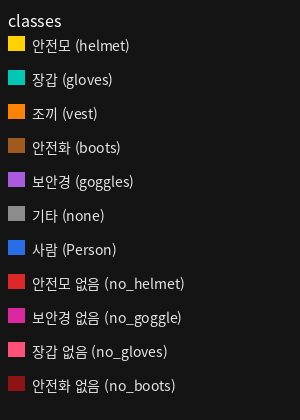


강의용 세 장. 왼쪽 입력, 오른쪽 정답


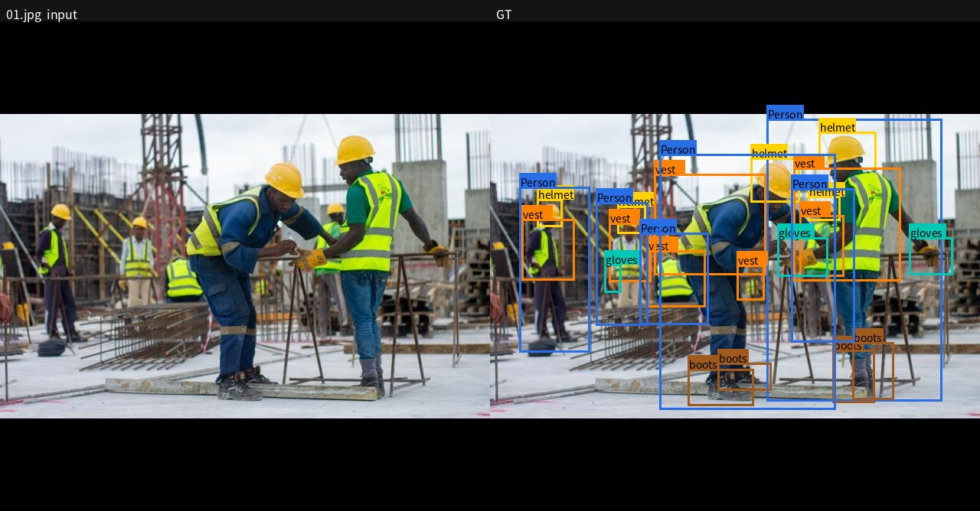

01.jpg 640x640  boxes 25
  안전모 (helmet)              5
  장갑 (gloves)               3
  조끼 (vest)                 7
  안전화 (boots)               4
  사람 (Person)               6



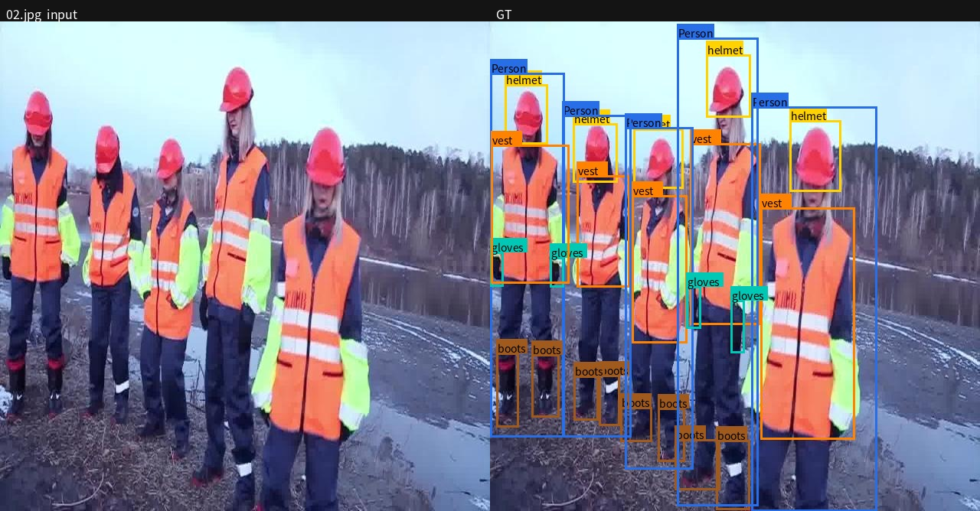

02.jpg 640x640  boxes 27
  안전모 (helmet)              5
  장갑 (gloves)               4
  조끼 (vest)                 5
  안전화 (boots)               8
  사람 (Person)               5



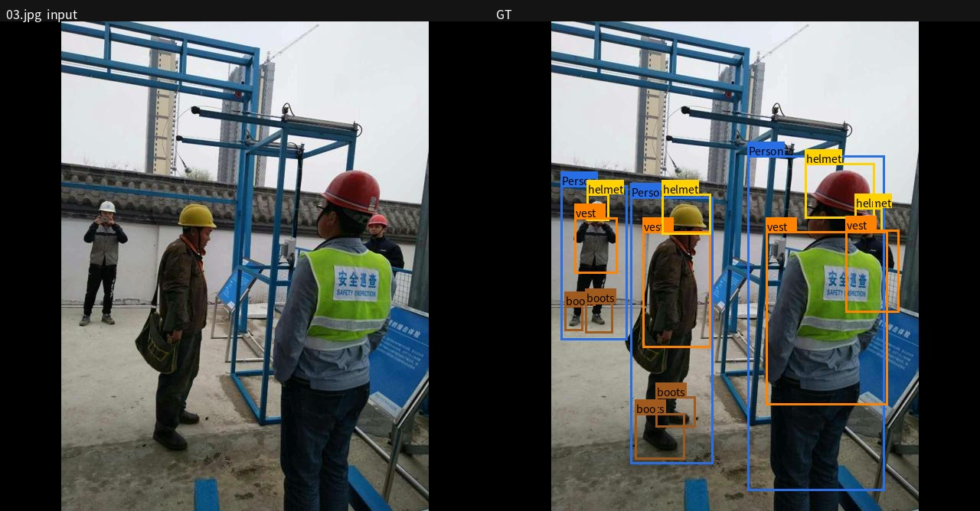

03.jpg 640x640  boxes 15
  안전모 (helmet)              4
  조끼 (vest)                 4
  안전화 (boots)               4
  사람 (Person)               3



In [8]:
from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

# 전체 검출 대상 클래스 개수 (11개)
NUM_CLASSES = 11

# 데이터셋에 정의된 영문 클래스 이름 목록
CLASS_NAMES = [
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles",
    "none",
    "Person",
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots",
]
# 이해를 돕기 위한 한글 클래스 이름 목록
CLASS_KO = [
    "안전모",
    "장갑",
    "조끼",
    "안전화",
    "보안경",
    "기타",
    "사람",
    "안전모 없음",
    "보안경 없음",
    "장갑 없음",
    "안전화 없음",
]
# 바운딩 박스 상단 텍스트 표시용 영문 클래스 이름 목록
CLASS_EN = [
    "helmet",
    "gloves",
    "vest",
    "boots",
    "goggles",
    "none",
    "Person",
    "no_helmet",
    "no_goggle",
    "no_gloves",
    "no_boots",
]
# 한글과 영문을 병기한 출력용 라벨 리스트 생성 (예: "안전모 (helmet)")
CLASS_LABEL = [
    ko if ko.lower() == en.lower() else f"{ko} ({en})"
    for ko, en in zip(CLASS_KO, CLASS_EN)
]
# 각 클래스 인덱스(0~10)에 대응하는 시각화용 RGB 색상 딕셔너리
DET_COLORS = {
    0: (255, 210, 0),   # helmet: 노란색 계열
    1: (0, 200, 180),   # gloves: 청록색 계열
    2: (255, 130, 0),   # vest: 주황색 계열
    3: (160, 90, 30),   # boots: 갈색 계열
    4: (170, 90, 220),  # goggles: 보라색 계열
    5: (140, 140, 140), # none: 회색 계열
    6: (40, 110, 230),  # Person: 파란색 계열
    7: (220, 40, 40),   # no_helmet: 빨간색 계열
    8: (220, 40, 160),  # no_goggle: 자주색 계열
    9: (255, 80, 120),  # no_gloves: 분홍색 계열
    10: (140, 20, 20),  # no_boots: 어두운 적갈색 계열
}


def hangul_font(size):
    """지정된 크기의 한글 폰트 객체를 반환하는 함수"""
    for path, index in (
        ("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc", 1),
        ("/usr/share/fonts/truetype/nanum/NanumGothic.ttf", None),
        ("/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf", None),
    ):
        if not Path(path).exists():
            continue
        try:
            kw = {"index": index} if index is not None else {}
            return ImageFont.truetype(path, size, **kw)
        except OSError:
            continue
    return None


def font_and_names(size):
    """한글 폰트 사용 가능 여부에 따라 적절한 폰트 객체와 클래스 이름 리스트(한영 병기 또는 영문 전용)를 반환"""
    found = hangul_font(size)
    if found is not None:
        return found, CLASS_LABEL
    # 한글 폰트가 없을 경우 기본 영문 폰트로 대체
    for path in (
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    ):
        try:
            return ImageFont.truetype(path, size), CLASS_EN
        except OSError:
            continue
    return ImageFont.load_default(), CLASS_EN


def font(size):
    """지정된 크기의 폰트 객체만 반환하는 헬퍼 함수"""
    found, _ = font_and_names(size)
    return found


def caption(img, text):
    """이미지 상단에 어두운 배경의 제목 표시줄(캡션 바)을 덧붙이는 함수"""
    bar_h = 28
    # 원본 이미지 높이보다 bar_h만큼 더 큰 새 캔버스 생성
    canvas = Image.new("RGB", (img.width, img.height + bar_h), (20, 20, 20))
    # 캡션 바 아래쪽에 원본 이미지 붙여넣기
    canvas.paste(img.convert("RGB"), (0, bar_h))
    draw = ImageDraw.Draw(canvas)
    # 상단 바에 흰색 텍스트로 캡션 작성
    draw.text((8, 6), text, fill=(255, 255, 255), font=font(16))
    return canvas


def side_by_side(left, right):
    """동일한 크기의 두 이미지를 좌우로 나란히 이어 붙이는 함수"""
    w, h = left.size
    canvas = Image.new("RGB", (w * 2, h))
    canvas.paste(left, (0, 0))
    canvas.paste(right, (w, 0))
    return canvas


def legend_panel(height):
    """11개 클래스의 색상과 이름을 보여주는 범례(Legend) 패널 이미지를 생성하는 함수"""
    f, names = font_and_names(14)
    title, _ = font_and_names(16)
    col_w = 300
    img = Image.new("RGB", (col_w, height), (20, 20, 20))
    draw = ImageDraw.Draw(img)
    draw.text((8, 8), "classes", fill=(255, 255, 255), font=title)
    # 높이에 맞춰 항목 간 세로 간격 계산
    gap = max(18, (height - 40) // NUM_CLASSES)
    for i, name in enumerate(names):
        y = 36 + i * gap
        # 클래스별 색상 사각형 아이콘과 텍스트 그리기
        draw.rectangle([8, y, 24, y + 14], fill=DET_COLORS[i])
        draw.text((32, y - 2), name, fill=(230, 230, 230), font=f)
    return img


def yolo_xyxy(line, width, height):
    """YOLO 포맷의 정규화된 라벨 문자열(cls, xc, yc, bw, bh)을 픽셀 단위의 좌상단·우하단 좌표(x1, y1, x2, y2)로 변환하는 함수"""
    cls, xc, yc, bw, bh = (float(p) for p in line.split())
    x1 = (xc - bw / 2.0) * width
    y1 = (yc - bh / 2.0) * height
    x2 = (xc + bw / 2.0) * width
    y2 = (yc + bh / 2.0) * height
    return int(cls), x1, y1, x2, y2


def gt_boxes(image):
    """이미지 파일과 동일한 이름의 .txt 라벨 파일을 읽어 정답 바운딩 박스 리스트를 반환하는 함수"""
    lab = image.parent / f"{image.stem}.txt"
    img = Image.open(image).convert("RGB")
    w, h = img.size
    boxes = []
    if lab.exists():
        for raw in lab.read_text().splitlines():
            if raw.strip():
                boxes.append(yolo_xyxy(raw, w, h))
    return boxes


# 1. 클래스별 색상 범례 출력
print("클래스 색")
legend = ROOT / "examples" / "legend.png"
if legend.exists():
    show_img(Image.open(legend), width=360)
else:
    show_img(legend_panel(420), width=360)

# 2. 강의용 샘플 이미지 3장에 대해 원본(input)과 정답(GT) 비교 시각화 및 객체 수 집계
print()
print("강의용 세 장. 왼쪽 입력, 오른쪽 정답")
for path in sorted((ROOT / "examples").glob("[0-9][0-9].jpg")):
    img = Image.open(path).convert("RGB")
    gt_path = path.parent / f"{path.stem}_gt.jpg"
    # 미리 그려진 GT 이미지가 있으면 불러오고, 크기가 다르면 원본에 맞춤
    if gt_path.exists():
        gt_panel = Image.open(gt_path).convert("RGB")
        if gt_panel.size != img.size:
            gt_panel = gt_panel.resize(img.size, Image.BILINEAR)
    else:
        gt_panel = img.copy()
    # 좌우로 나란히 이어 붙여 출력
    show_img(
        side_by_side(caption(img, f"{path.name}  input"), caption(gt_panel, "GT")),
        width=980,
    )
    # 정답 텍스트 파일에서 박스 정보를 읽어 클래스별 개수 카운트 및 출력
    boxes = gt_boxes(path)
    counts = Counter(cls for cls, *_ in boxes)
    print(path.name, f"{img.size[0]}x{img.size[1]}  boxes {len(boxes)}")
    for c in range(NUM_CLASSES):
        n = int(counts.get(c, 0))
        if n:
            print(f"  {CLASS_LABEL[c]:24s}  {n}")
    print()


### 객체 검출(Object Detection)을 통한 PPE 착용 판별 원리

방금 확인한 장면들은 **객체 검출(Object Detection)** 기법으로 해결합니다. 한 사람에 대해 전체 몸통을 감싸는 박스(`Person`) 하나를 그리고, 그 사람이 착용한 안전모·조끼·장갑·안전화마다 각각 별도의 박스를 그립니다. 즉, 한 작업자에게 속한 보호구라도 모델은 각각의 장비를 독립된 객체로 인식하고 검출합니다.

이렇게 바운딩 박스를 찾으면 *"현재 화면에 안전모가 총 몇 개 있는가?"*, *"안전조끼를 입지 않은 작업자가 있는가?"*와 같은 질문에 개수와 위치로 즉시 답할 수 있습니다. 픽셀 단위로 영역을 색칠하는 세그멘테이션(Segmentation)은 장비의 정밀한 윤곽선까지 찾아내지만, 현장 안전 관리처럼 위치 파악과 개수 집계가 핵심인 과제에서는 직사각형 박스 검출만으로도 충분히 빠르고 효과적입니다.

또한, 이 데이터셋에는 **보호구를 착용하지 않은 상태**를 직접 가리키는 클래스도 정의되어 있습니다. 예를 들어 `안전모 없음 (no_helmet)`이나 `장갑 없음 (no_gloves)`처럼 이름에 '없음(no_)'이 포함된 클래스는 안전장비를 착용해야 할 신체 부위(머리, 손 등)에 장비가 없는 상태를 박스로 직접 표시한 것입니다.

*참고: 위에서 본 샘플 3장은 공사 현장의 특징이 뚜렷한 사진들이지만, 전체 테스트 세트 안에는 일반 일상 사진처럼 공사 현장이 아닌 이미지도 일부 포함되어 있어 모델의 오탐지(False Positive) 대처 능력을 함께 시험하게 됩니다.*


## 5. 모델 아키텍처 (Ultralytics YOLO26n)

모델에 입력 이미지 한 장을 넣으면 검출된 각 객체마다 **클래스(Class), 직사각형 좌표(xyxy), 신뢰도(Confidence Score)**가 출력됩니다. 이때 신뢰도가 `0.25`보다 낮은 불확실한 후보 박스는 버리고, 동일한 물체를 가리키는 중복 박스들이 여러 개 겹쳐 있을 때는 **NMS(Non-Maximum Suppression, 비최대 억제)** 알고리즘을 통해 가장 신뢰도가 높은 박스 하나만 남깁니다. 우리가 시연에서 보는 깔끔한 결과 이미지는 이러한 후처리 과정을 거쳐 최종 선택된 박스들을 그린 것입니다.

**YOLO(You Only Look Once)** 아키텍처는 입력 이미지를 여러 해상도의 격자(Grid, Stride 8 / 16 / 32)로 나누고 각 칸마다 박스 후보를 예측합니다. 덕분에 크기가 작은 안전모나 장갑은 촘촘한 고해상도 격자에서, 큼직한 사람 몸통은 성긴 저해상도 격자에서 효과적으로 잡아낼 수 있습니다.

본 실습에서 사용하는 **Ultralytics YOLO26n**은 대규모 데이터셋인 COCO(80개 클래스)로 사전 학습된 경량화(Nano) 검출기 모델로, 전체 파라미터 수가 약 250만 개에 불과해 연산 속도가 매우 빠릅니다. 이 과제에서는 백본(Backbone)과 넥(Neck)의 시각 특징 추출 능력은 그대로 활용하고, 마지막 검출 헤드(Detect Head)만 공사 현장 PPE **11개 클래스**에 맞게 교체하여 전이 학습(Transfer Learning)을 수행합니다.

아래 코드의 `show_yolo_stack()` 함수는 사전 학습된 가중치를 불러와 파라미터 수를 계산하고, 입력부터 NMS 출력까지의 전체 파이프라인을 다이어그램으로 시각화합니다.


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


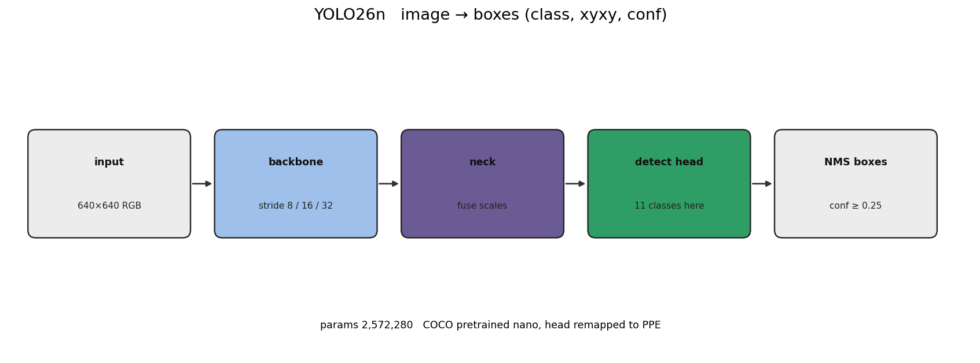

In [9]:
from io import BytesIO

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from ultralytics import YOLO


def show_yolo_stack():
    """YOLO26n 모델의 전체 추론 파이프라인과 파라미터 수를 다이어그램으로 그려 출력하는 함수"""
    # 사전 학습된 YOLO26n 가중치 파일 로드 및 전체 파라미터 개수 합산
    pretrained = ROOT / "weights" / "yolo26n.pt"
    model = YOLO(str(pretrained))
    n = sum(p.numel() for p in model.model.parameters())

    # 다이어그램을 그릴 Matplotlib 캔버스 설정
    fig, ax = plt.subplots(figsize=(12.2, 4.6))
    ax.set_xlim(0, 12.4)
    ax.set_ylim(0.2, 4.4)
    ax.axis("off")
    ax.set_title("YOLO26n   image → boxes (class, xyxy, conf)", fontsize=14, pad=8)
    boxes = {}

    def box(key, cx, cy, title, sub, color, bw=2.05, bh=1.35):
        """모서리가 둥근 사각형 블록과 내부 텍스트를 그리는 내부 헬퍼 함수"""
        patch = FancyBboxPatch(
            (cx - bw / 2, cy - bh / 2),
            bw,
            bh,
            boxstyle="round,pad=0.02,rounding_size=0.1",
            facecolor=color,
            edgecolor="#222",
            linewidth=1.2,
        )
        ax.add_patch(patch)
        ax.text(cx, cy + 0.28, title, ha="center", va="center", fontsize=9, fontweight="bold", color="#111")
        ax.text(cx, cy - 0.28, sub, ha="center", va="center", fontsize=8, color="#222")
        boxes[key] = (cx, cy, bw, bh)

    def arrow(src, dst, text=""):
        """두 블록 사이를 연결하는 화살표를 그리는 내부 헬퍼 함수"""
        x1, y1, w1, _ = boxes[src]
        x2, y2, w2, _ = boxes[dst]
        ax.annotate(
            "",
            xy=(x2 - w2 / 2 - 0.02, y2),
            xytext=(x1 + w1 / 2 + 0.02, y1),
            arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.4, mutation_scale=10),
        )
        if text:
            ax.text((x1 + x2) / 2, y1 + 0.85, text, ha="center", fontsize=7.5, color="#444")

    # YOLO 파이프라인의 5단계 구성 요소(입력 -> 백본 -> 넥 -> 검출 헤드 -> NMS 출력) 블록 배치
    box("in", 1.3, 2.4, "input", "640×640 RGB", "#ececec")
    box("back", 3.7, 2.4, "backbone", "stride 8 / 16 / 32", "#9ec0ea")
    box("neck", 6.1, 2.4, "neck", "fuse scales", "#6b5b95")
    box("head", 8.5, 2.4, "detect head", "11 classes here", "#2f9e66")
    box("out", 10.9, 2.4, "NMS boxes", "conf ≥ 0.25", "#ececec")

    # 블록 간 데이터 흐름 화살표 연결
    arrow("in", "back")
    arrow("back", "neck")
    arrow("neck", "head")
    arrow("head", "out")

    # 하단에 총 파라미터 수 및 모델 요약 설명 추가
    ax.text(6.2, 0.55, f"params {n:,}   COCO pretrained nano, head remapped to PPE", ha="center", fontsize=9)
    fig.tight_layout()

    # 그린 그래프를 메모리 버퍼(BytesIO)에 PNG로 저장한 뒤 PIL 이미지로 변환하여 출력
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    buf.seek(0)
    show_img(Image.open(buf), width=980)


# 아키텍처 다이어그램 출력 실행
show_yolo_stack()


## 6. 모델 학습 (Training)

객체 검출 모델의 핵심 평가지표인 **mAP50(mean Average Precision at IoU=0.50)**은 예측한 박스와 실제 정답 박스의 겹치는 비율(IoU, Intersection over Union)이 `0.5` 이상일 때 올바르게 검출한 것으로 인정하고, 각 클래스별 정밀도-재현율 곡선 아래 면적(Average Precision, AP)을 구해 전체 클래스에 대해 평균을 낸 값입니다. `0`에서 `1` 사이의 값을 가지며, `1`에 가까울수록 객체의 위치와 종류를 모두 정확하게 찾아냈음을 의미합니다.

바운딩 박스가 아주 미세하게 어긋나더라도 같은 물체를 잘 감싸고 있다면 IoU 0.5를 넘기 때문에, 학습 과정에서는 매 에폭(Epoch)마다 **검증 세트(Validation Set)**의 성능을 측정하여 점수가 가장 높은 최적의 가중치(`best.pt`)를 자동으로 저장합니다. 이때 검증 세트는 좋은 모델을 고르기 위한 기준일 뿐이며, 최종적인 성능 평가는 학습이나 모델 선택에 전혀 관여하지 않은 **테스트 세트(Test Set)**로 수행해야 공정합니다.

아래 학습 코드는 공식 Construction-PPE 튜토리얼과 동일하게 `5 epoch` 동안 학습을 진행합니다. 실습 편의를 위해 원본 압축 파일에 들어 있던 가중치(`runs/train/weights/best.pt`)는 덮어쓰지 않고, 새로운 폴더인 `runs/train_colab/weights/best.pt`에 결과를 별도로 저장합니다.

*(빠르게 평가와 추론 시연만 확인하고 싶다면 이 셀의 실행을 건너뛰어도 무방합니다.)*


In [10]:
from pathlib import Path
from ultralytics import YOLO

# 학습 하이퍼파라미터 설정: 총 5 에폭, 입력 이미지 크기 640x640
EPOCHS = 5
IMGSZ = 640

# 사전 학습된 YOLO26n 가중치 파일 존재 여부 확인
pretrained = ROOT / "weights" / "yolo26n.pt"
if not pretrained.exists():
    raise SystemExit(f"사전학습 가중치가 없다: {pretrained}")

# YOLO 학습에 필요한 데이터셋 경로 및 클래스 정보를 담은 YAML 설정 파일 생성
data_yaml = ROOT / "runs" / "data_resolved.yaml"
data_yaml.parent.mkdir(parents=True, exist_ok=True)
names = "\n".join(f"  {i}: {n}" for i, n in enumerate(CLASS_NAMES))
data_yaml.write_text(
    f"path: {ROOT / 'dataset'}\n"
    "train: images/train\n"
    "val: images/val\n"
    "test: images/test\n"
    f"names:\n{names}\n",
    encoding="utf-8",
)

# 코랩 학습 결과를 저장할 디렉터리 경로 지정 (기존 best.pt 보존을 위해 train_colab으로 분리)
out_dir = ROOT / "runs" / "train_colab"

# 사전 학습 모델 로드 및 커스텀 데이터셋 학습 시작
model = YOLO(str(pretrained))
model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    project=str(ROOT / "runs"),
    name="train_colab",
    exist_ok=True,
)

# 새로 학습된 최적 가중치 경로와 기존 보존된 가중치 경로 안내 출력
print("saved", out_dir / "weights" / "best.pt")
print("zip best.pt unchanged", ROOT / "runs" / "train" / "weights" / "best.pt")


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/object_detection/runs/data_resolved.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/object_detection/weights/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_co

## 7. 테스트 데이터셋 정량 평가 (Evaluation)

모델 학습과 체크포인트 선택 과정에서 한 번도 사용하지 않은 **독립된 테스트 데이터셋(Held-out Test Set)**을 사용하여 최종 성능을 평가합니다. 기본적으로 압축 파일에 포함된 학습 완료 가중치(`runs/train/weights/best.pt`)를 평가하며, 만약 6번 섹션에서 직접 학습한 가중치를 평가해 보고 싶다면 `WEIGHTS` 변수의 경로를 `runs/train_colab/weights/best.pt`로 변경하면 됩니다.

출력 결과의 첫 줄에 나오는 지표들의 의미는 다음과 같습니다:
- **`mAP50`**: IoU 임계값을 `0.50`으로 설정했을 때 모든 클래스의 AP를 평균 낸 값입니다.
- **`mAP50-95`**: IoU 임계값을 `0.50`부터 `0.95`까지 `0.05` 단위로 엄격하게 높여가며 측정한 AP들의 평균값입니다. 박스 위치가 정답과 훨씬 더 정교하게 일치해야 높은 점수를 받으므로 `mAP50`보다 수치가 낮게 나타납니다.

그 아래에는 **11개 각 클래스별 `AP50` 점수**가 출력됩니다. 점수가 높을수록 해당 보호구나 사람을 놓치지 않고 정확히 검출했다는 뜻이고, 점수가 낮다면 미검출(False Negative)되거나 다른 클래스로 오분류(False Positive)된 경우가 많다는 뜻입니다. 전체 `mAP`는 각 클래스의 AP를 동일한 비중(산술 평균)으로 합산하므로, 현장에 자주 등장하는 '사람(Person)' 클래스와 드물게 등장하는 '보안경(goggles)' 클래스가 평균 점수에 같은 비율로 반영됩니다.

*참고: 테스트 데이터셋 내부에 공사 현장이 아닌 일반 배경 이미지가 섞여 있을 경우, 일반인의 머리를 `안전모 없음 (no_helmet)`으로 예측하거나 배경에서 오탐지가 발생해 해당 클래스의 점수와 전체 평균이 다소 낮아질 수 있습니다.*


In [11]:
import json
from pathlib import Path
from ultralytics import YOLO

# 평가에 사용할 학습 완료 가중치 경로 설정 (직접 학습한 모델을 쓰려면 train_colab으로 변경)
WEIGHTS = ROOT / "runs" / "train" / "weights" / "best.pt"
print("weights", WEIGHTS)

# 6번 학습 셀을 건너뛰었을 경우를 대비해 데이터셋 설정 YAML 파일이 없으면 자동 생성
data_yaml = ROOT / "runs" / "data_resolved.yaml"
if not data_yaml.exists():
    data_yaml.parent.mkdir(parents=True, exist_ok=True)
    names = "\n".join(f"  {i}: {n}" for i, n in enumerate(CLASS_NAMES))
    data_yaml.write_text(
        f"path: {ROOT / 'dataset'}\n"
        "train: images/train\n"
        "val: images/val\n"
        "test: images/test\n"
        f"names:\n{names}\n",
        encoding="utf-8",
    )

# 가중치를 불러와 테스트 분할(split='test') 데이터셋에 대해 검증(평가) 수행
model = YOLO(str(WEIGHTS))
metrics = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    plots=False,
)

# 테스트 폴더 내 전체 이미지 파일 개수 확인
test_dir = ROOT / "dataset" / "images" / "test"
n_img = sum(1 for p in test_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})

# 전체 테스트셋에 대한 mAP50 및 mAP50-95 요약 지표 출력
maps = list(metrics.box.ap50)
print(
    f"held_out_test  n={n_img}  "
    f"mAP50 {float(metrics.box.map50):.3f}  mAP50-95 {float(metrics.box.map):.3f}"
)

# 각 클래스별 AP50 점수를 순회하며 출력 및 딕셔너리에 저장
per = {}
for i, name in enumerate(CLASS_NAMES):
    ap = float(maps[i]) if i < len(maps) else 0.0
    label = CLASS_LABEL[i]
    per[label] = round(ap, 4)
    print(f"  {label:24s}  AP50 {ap:.3f}")

# 평가 결과 지표들을 JSON 파일로 정리하여 저장
report = {
    "n": n_img,
    "n_classes": int(metrics.box.nc),
    "map50": round(float(metrics.box.map50), 4),
    "map50_95": round(float(metrics.box.map), 4),
    "precision": round(float(metrics.box.mp), 4),
    "recall": round(float(metrics.box.mr), 4),
    "per_class_ap50": per,
}
out = ROOT / "runs" / "test_metrics.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", out)


weights /content/object_detection/runs/train/weights/best.pt
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,376,981 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1851.8±712.3 MB/s, size: 96.5 KB)
val: Scanning /content/object_detection/dataset/labels/test... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 1.9Kit/s 0.1s
val: New cache created: /content/object_detection/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.8it/s 1.9s
                   all        141       1251      0.581      0.538      0.551      0.278
                helmet        110        192      0.921      0.912      0.942      0.502
                gloves         75        163       0.83      0.755      0.779      0.389
                  vest        111        178      0.836      0.876      0.902  

## 8. 샘플 이미지 추론 및 결과 비교 시연 (Inference)

학습된 YOLO 모델을 사용하여 샘플 이미지 3장에 대해 실제 추론(Inference)을 수행하고, **왼쪽부터 순서대로 [원본 입력(input) - 실제 정답(GT) - YOLO 예측 결과(YOLO) - 색상 범례(classes)]**를 한 화면에 나란히 이어 붙여 비교합니다.

7번 평가 섹션과 마찬가지로 기본값은 압축 파일의 `runs/train/weights/best.pt`를 사용하며, 6번에서 직접 학습한 모델을 시연해 보려면 `WEIGHTS` 경로를 `runs/train_colab/weights/best.pt`로 변경하면 됩니다.

시각화 결과를 살펴보면 주요 클래스인 **사람(Person), 안전모(helmet), 조끼(vest)** 등은 모델이 매우 높은 신뢰도로 정확하게 찾아내는 것을 확인할 수 있습니다. 이미지 상단에 함께 출력되는 숫자는 해당 이미지 한 장에서 검출된 클래스별 바운딩 박스의 개수(GT 개수 vs 예측 개수)를 나타내며, 7번에서 확인한 전체 테스트 세트 평가지표(mAP)와는 구분해서 해석해야 합니다.


weights /content/object_detection/runs/train/weights/best.pt
01.jpg
  GT
    안전모 (helmet)              5
    장갑 (gloves)               3
    조끼 (vest)                 7
    안전화 (boots)               4
    사람 (Person)               6
  pred
    안전모 (helmet)              5
    장갑 (gloves)               4
    조끼 (vest)                 5
    안전화 (boots)               4
    사람 (Person)               4


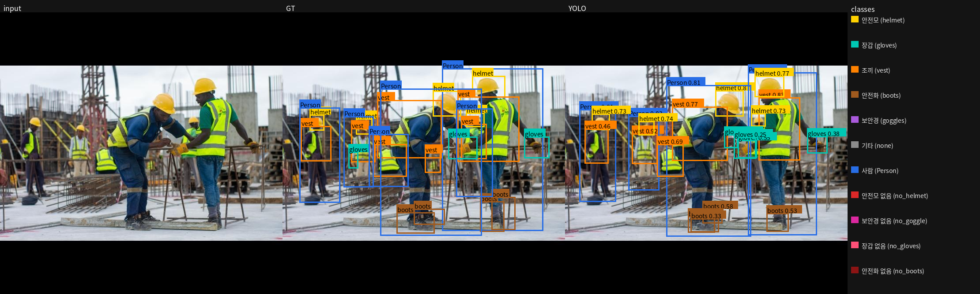


02.jpg
  GT
    안전모 (helmet)              5
    장갑 (gloves)               4
    조끼 (vest)                 5
    안전화 (boots)               8
    사람 (Person)               5
  pred
    안전모 (helmet)              5
    조끼 (vest)                 5
    안전화 (boots)               9
    사람 (Person)               5


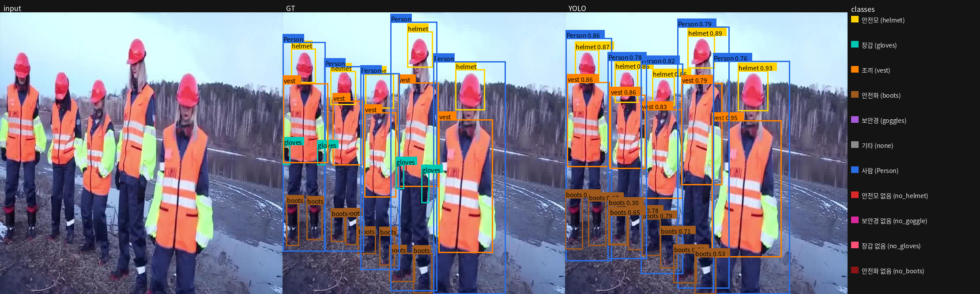


03.jpg
  GT
    안전모 (helmet)              4
    조끼 (vest)                 4
    안전화 (boots)               4
    사람 (Person)               3
  pred
    안전모 (helmet)              4
    조끼 (vest)                 1
    안전화 (boots)               4
    기타 (none)                 3
    사람 (Person)               3


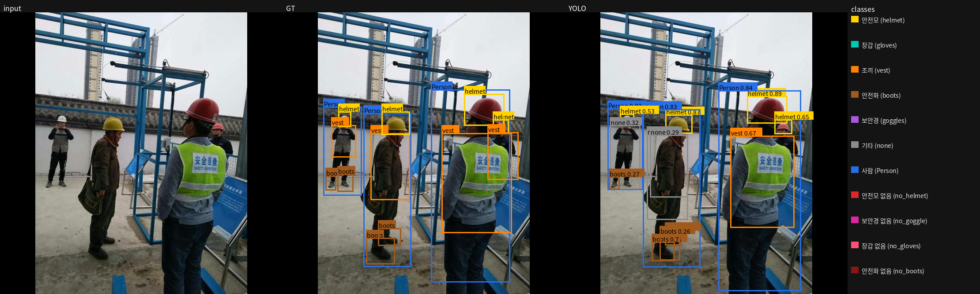

In [12]:
from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from ultralytics import YOLO


def draw_boxes(img, boxes, with_conf):
    """이미지 위에 바운딩 박스와 클래스 라벨(및 신뢰도 점수)을 그리고 클래스별 검출 개수를 반환하는 함수"""
    canvas = img.convert("RGB").copy()
    draw = ImageDraw.Draw(canvas)
    f = font(14)
    # 각 클래스별 검출 개수를 0으로 초기화
    counts = {name: 0 for name in CLASS_NAMES}

    for item in boxes:
        cls, x1, y1, x2, y2 = item[:5]
        conf = item[5] if len(item) > 5 else None
        # 유효한 클래스 인덱스 범위를 벗어나면 무시
        if not (0 <= cls < NUM_CLASSES):
            continue
        color = DET_COLORS[cls]
        name = CLASS_NAMES[cls]
        counts[name] += 1

        # 신뢰도 표시 옵션(with_conf)이 켜져 있으면 클래스명 옆에 소수점 둘째 자리까지 신뢰도 병기
        label = CLASS_EN[cls] if (conf is None or not with_conf) else f"{CLASS_EN[cls]} {conf:.2f}"
        x1, y1, x2, y2 = int(x1), int(y1), int(x2), int(y2)

        # 객체 외곽선 바운딩 박스 그리기 (두께 3)
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        # 텍스트 가독성을 위해 박스 좌상단에 배경 색상 라벨 패치 그리기
        tw = max(8 * len(label), 40)
        draw.rectangle([x1, max(0, y1 - 18), x1 + tw, y1], fill=color)
        # 라벨 패치 위에 검은색 글씨로 클래스명(및 신뢰도) 작성
        draw.text((x1 + 2, max(0, y1 - 17)), label, fill=(0, 0, 0), font=f)
    return canvas, counts


def pred_boxes(result):
    """Ultralytics YOLO 추론 결과 객체(Results)에서 바운딩 박스 정보(클래스, 좌표, 신뢰도)를 추출하는 함수"""
    out = []
    if result.boxes is None:
        return out
    for b in result.boxes:
        cls = int(b.cls.item())
        conf = float(b.conf.item())
        x1, y1, x2, y2 = (float(v) for v in b.xyxy[0].tolist())
        out.append((cls, x1, y1, x2, y2, conf))
    return out


# 추론에 사용할 가중치 파일 로드
WEIGHTS = ROOT / "runs" / "train" / "weights" / "best.pt"
print("weights", WEIGHTS)
model = YOLO(str(WEIGHTS))

# 시연용 샘플 이미지 목록을 불러와 신뢰도 임계값(conf=0.25)으로 추론 실행
images = sorted((ROOT / "examples").glob("[0-9][0-9].jpg"))
results = model.predict(
    source=[str(p) for p in images],
    conf=0.25,
    verbose=False,
    save=False,
)

# 추론 시각화 결과 이미지를 저장할 폴더 생성
out_dir = ROOT / "runs" / "infer"
out_dir.mkdir(parents=True, exist_ok=True)

# 각 샘플 이미지별로 원본, 정답(GT), 예측(YOLO), 범례를 하나로 합쳐 출력 및 저장
for path, r in zip(images, results):
    raw = Image.open(path).convert("RGB")
    # 추론 결과의 원본 해상도 정보와 이미지 크기를 일치시킴
    if r.orig_shape is not None:
        oh, ow = int(r.orig_shape[0]), int(r.orig_shape[1])
        view = raw.resize((ow, oh), Image.BILINEAR) if raw.size != (ow, oh) else raw
    else:
        view = raw

    # 정답 박스 이미지(신뢰도 미표시)와 모델 예측 박스 이미지(신뢰도 표시) 생성
    gt = draw_boxes(view, gt_boxes(path), with_conf=False)[0]
    pred = pred_boxes(r)
    pred_img, counts = draw_boxes(view, pred, with_conf=True)

    # 각 패널 상단에 캡션(input, GT, YOLO) 추가
    panels = [
        caption(view, "input"),
        caption(gt, "GT"),
        caption(pred_img, "YOLO"),
    ]
    w, h = panels[0].size
    leg = legend_panel(h)

    # 3개의 이미지 패널과 우측 범례 패널을 가로로 나란히 붙일 통합 캔버스 생성
    canvas = Image.new("RGB", (w * 3 + leg.width, h))
    for i, panel in enumerate(panels):
        canvas.paste(panel, (i * w, 0))
    canvas.paste(leg, (w * 3, 0))

    # 완성된 비교 이미지를 파일로 저장
    out = out_dir / f"{path.stem}_pred.jpg"
    canvas.save(out, quality=92)

    # 콘솔에 정답(GT) 객체 수와 모델 예측(pred) 객체 수를 클래스별로 비교 출력
    gt_counts = Counter(cls for cls, *_ in gt_boxes(path))
    print(path.name)
    print("  GT")
    for c in range(NUM_CLASSES):
        n = int(gt_counts.get(c, 0))
        if n:
            print(f"    {CLASS_LABEL[c]:24s}  {n}")
    print("  pred")
    for name in CLASS_NAMES:
        if counts[name]:
            print(f"    {CLASS_LABEL[CLASS_NAMES.index(name)]:24s}  {counts[name]}")

    # 노트북 화면에 최종 비교 이미지 출력
    show_img(canvas, width=980)
    print()
